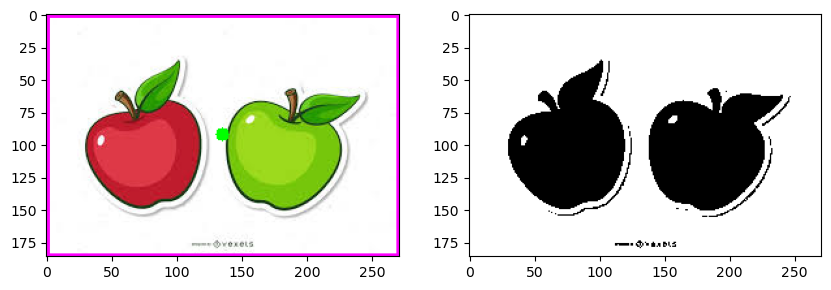

contornos 1: Perimetros=[[...]], Area=34.813151999999995


In [43]:
import  cv2
import matplotlib.pyplot as plt
import numpy as np


cm = 0.0264

imagen = cv2.imread('../imagenes/Apples.jpeg')
gray=cv2.cvtColor(imagen,cv2.COLOR_BGR2GRAY)
ret,bin=cv2.threshold(gray,200,255,cv2.THRESH_BINARY)
contorno,jeraquia=cv2.findContours(bin,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
perimetros=[]
areaa=[]
for i in range(len(contorno)):
    cont=contorno[i]
    M=cv2.moments(cont)
    if M['m00']!=0:
        cx=int(M['m10']/M['m00'])
        cy=int(M['m01']/M['m00'])
    else:
        cx,cy=0,0
    area=cv2.contourArea(cont) *(cm**2)
    perimetro=cv2.arcLength(cont,True) *cm
    
    perimetros.append(perimetros)
    areaa.append(area)

    cv2.circle(imagen,(cx,cy),5,(0,255,0),-1)
    x,y,w,h=cv2.boundingRect(cont)
    cv2.rectangle(imagen,(x,y),(x+w,y+h),(255,0,255),3)


plt.figure(figsize=(10,5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(imagen,cv2.COLOR_BGR2RGB))

plt.subplot(122)
plt.imshow(bin,cmap='gray')

plt.show()

for i ,(perimetro,area) in enumerate(zip(perimetros,areaa)):
    print(f'contornos {i+1}: Perimetros={perimetro}, Area={area}')



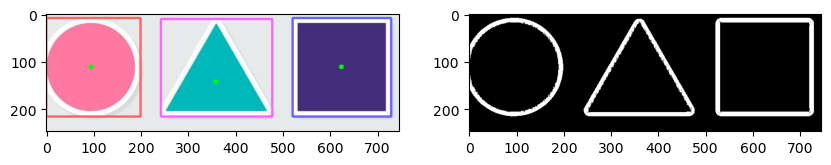

Contorno 1: Perímetro=740.340181350708, Área=27006.5, Vértices aproximados=3
Contorno 2: Perímetro=811.5979789495468, Área=42728.0, Vértices aproximados=4
Contorno 3: Perímetro=679.9554060697556, Área=33141.0, Vértices aproximados=8


In [44]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

imagen = cv2.imread('../imagenes/figuras3.png')
gray = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
ret, bin = cv2.threshold(gray, 247, 255, cv2.THRESH_BINARY , cv2.THRESH_OTSU)
contorno, jeraquia = cv2.findContours(bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
perimetros = []
areaa = []
vertices = []

for i in range(len(contorno)):
    cont = contorno[i]
    M = cv2.moments(cont)
    if M['m00'] != 0:
        cx = int(M['m10'] / M['m00'])
        cy = int(M['m01'] / M['m00'])
    else:
        cx, cy = 0, 0
    area = cv2.contourArea(cont)
    perimetro = cv2.arcLength(cont, True)
    epsilon = 0.02 * perimetro  
    vertice = cv2.approxPolyDP(cont, epsilon, True) 

    perimetros.append(perimetro)
    areaa.append(area)

    vertices.append(len(vertice))

    cv2.circle(imagen, (cx, cy), 5, (0, 255, 0), -1)
    x, y, w, h = cv2.boundingRect(cont)
    if len(vertice)==3:
        cv2.rectangle(imagen, (x, y), (x + w, y + h), (255, 100, 255), 3) #triangulo
    
    if len(vertice)==4:
        cv2.rectangle(imagen, (x, y), (x + w, y + h), (255, 100, 100), 3) #cuadrado
    
    if len(vertice)==8:
        cv2.rectangle(imagen, (x, y), (x + w, y + h), (100, 100, 255), 3) #circulo
    

plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))

plt.subplot(122)
plt.imshow(bin, cmap='gray')

plt.show()

for i, (perimetro, area) in enumerate(zip(perimetros, areaa)):
    print(f'Contorno {i + 1}: Perímetro={perimetro}, Área={area}, Vértices aproximados={vertices[i]}')
